# **AIML Lab Mini Project**
 ## The objective of this miniproject is to develop a model which is multilanguage assistive, helps visually impaired users by describing images in multiple Indian languages and narrating the descriptions via audio. ##
 ## For achieving the task I have used pretrained models Vision Transformer(ViT) , IndicTrans2 and gTTS(Google-Text-To-Speech) models for image captioning, caption translation and text to speech conversion respectively.







## **Downloading Dataset**
I have taken the dataset for this project from [Flickr30k](https://datasets.activeloop.ai/docs/ml/datasets/flickr30k-dataset/).


In [ ]:
!pip install deeplake

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 617.0/617.0 kB 14.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 101.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.2/139.2 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 97.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 67.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 117.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 5.3 MB/s eta

In [ ]:
import deeplake
from PIL import Image
import os
import random

In [ ]:
ds = deeplake.load('hub://activeloop/flickr30k')

|

Opening dataset in read-only mode as you don't have write permissions.


|

This dataset can be visualized in Jupyter Notebook by ds.visualize() or at https://app.activeloop.ai/activeloop/flickr30k



|

hub://activeloop/flickr30k loaded successfully.



In [ ]:
os.makedirs('flickr30_images', exist_ok=True)
num_images_to_download = 100
for i in range(min(num_images_to_download, len(ds.image))):  # Ensure we don't exceed available images
    image = ds.image[i].numpy()  # Get the image as a numpy array
    image_file = f"flickr30_images/image_{i}.png"
    Image.fromarray(image).save(image_file)

/usr/local/lib/python3.10/dist-packages/deeplake/core/tensor.py:719: UserWarning: Indexing by integer in a for loop, like `for i in range(len(ds)): ... ds.tensor[i]` can be quite slow. Use `for i, sample in enumerate(ds)` instead.
  warnings.warn(


## **Image Captioning**
The Vision Transformer (ViT) is used to find objects in images and create captions. Images are first resized and normalized for processing. ViT then identifies the objects and generates simple descriptions, making it easy to understand the content quickly and efficiently.

In [ ]:
import requests
import torch
from PIL import Image
from transformers import VisionEncoderDecoderModel, ViTImageProcessor, GPT2TokenizerFast
from tqdm import tqdm


device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
from transformers import ViTForImageClassification, ViTFeatureExtractor



image_model = VisionEncoderDecoderModel.from_pretrained("nlpconnect/vit-gpt2-image-captioning").to(device)
image_tokenizer = GPT2TokenizerFast.from_pretrained("nlpconnect/vit-gpt2-image-captioning")
image_processor = ViTImageProcessor.from_pretrained("nlpconnect/vit-gpt2-image-captioning")

image_model.eval()

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/4.61k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/982M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/241 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/120 [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/228 [00:00<?, ?B/s]

VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_featur

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def display_image(image_path):
    img = mpimg.imread(image_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

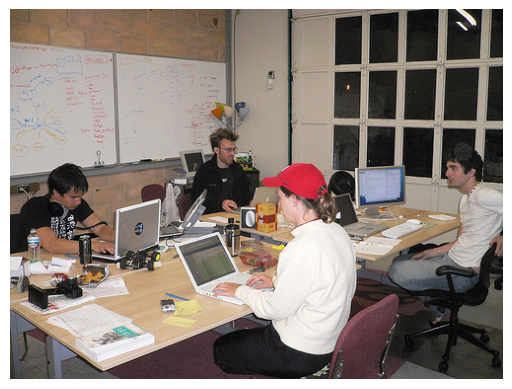

In [ ]:
display_image('/content/flickr30_images/image_95.png')

In [ ]:
'''
function for generating captions for a single image.
'''


def generate_caption(image_path):
    image = Image.open(image_path)
    pixel_values = image_processor(images=image, return_tensors="pt").pixel_values.to(device)

    generated_ids = image_model.generate(pixel_values, max_length=16, num_beams=4)

    caption = image_tokenizer.decode(generated_ids[0], skip_special_tokens=True)

    return caption

In [ ]:
describe = generate_caption('/content/flickr30_images/image_95.png')
describe


'a classroom full of people working on computers '

## **Caption translation**
The **IndicTransToolkit** is used to translate the captions into different Indian languages. After ViT generates the captions in English, this toolkit helps convert them into languages like Hindi, Tamil, and Bengali. This way, the user can understand the descriptions in their own language, making it easier and more accessible.

In [ ]:
%%capture
!git clone https://github.com/AI4Bharat/IndicTrans2.git

In [ ]:
%%capture
%cd /content/IndicTrans2/huggingface_interface

In [ ]:
!git clone https://github.com/VarunGumma/IndicTransToolkit
%cd IndicTransToolkit

!pip install --editable ./

Cloning into 'IndicTransToolkit'...
remote: Enumerating objects: 155, done.
remote: Counting objects: 100% (60/60), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 155 (delta 34), reused 45 (delta 30), pack-reused 95 (from 1)
Receiving objects: 100% (155/155), 3.88 MiB | 19.55 MiB/s, done.
Resolving deltas: 100% (62/62), done.
/content/IndicTrans2/huggingface_interface/IndicTransToolkit
Obtaining file:///content/IndicTrans2/huggingface_interface/IndicTransToolkit
  Preparing metadata (setup.py) ... done
  Cloning https://github.com/VarunGumma/indic_nlp_library to /tmp/pip-install-lzu1h93g/indic-nlp-library-it2_15ce3e58abf24ce599cf396872b2ddbb
  Running command git clone --filter=blob:none --quiet https://github.com/VarunGumma/indic_nlp_library /tmp/pip-install-lzu1h93g/indic-nlp-library-it2_15ce3e58abf24ce599cf396872b2ddbb
  Resolved https://github.com/VarunGumma/indic_nlp_library to commit 601521e05ed0ed8f2165ac317a47d186e25b6f0d
  Preparing metadata (setup.py) ..

In [ ]:
import torch
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
from IndicTransToolkit import IndicProcessor


In [ ]:
ip = IndicProcessor(inference=True)
tokenizer = AutoTokenizer.from_pretrained("ai4bharat/indictrans2-en-indic-dist-200M", trust_remote_code=True)
model = AutoModelForSeq2SeqLM.from_pretrained("ai4bharat/indictrans2-en-indic-dist-200M", trust_remote_code=True)




tokenizer_config.json:   0%|          | 0.00/1.11k [00:00<?, ?B/s]

tokenization_indictrans.py:   0%|          | 0.00/8.10k [00:00<?, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-en-indic-dist-200M:
- tokenization_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


dict.SRC.json:   0%|          | 0.00/645k [00:00<?, ?B/s]

dict.TGT.json:   0%|          | 0.00/3.39M [00:00<?, ?B/s]

model.SRC:   0%|          | 0.00/759k [00:00<?, ?B/s]

... (5 outputs left out)

modeling_indictrans.py:   0%|          | 0.00/79.6k [00:00<?, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-en-indic-dist-200M:
- modeling_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/1.10G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

In [ ]:
def translate_sentences(sentences, model, tokenizer, ip, src_lang="eng_Latn", tgt_lang="tel_Telu", num_beams=5, max_length=256):
    batch = ip.preprocess_batch(sentences, src_lang=src_lang, tgt_lang=tgt_lang)
    batch = tokenizer(batch, padding="longest", truncation=True, max_length=max_length, return_tensors="pt")

    with torch.inference_mode():
        outputs = model.generate(**batch, num_beams=num_beams, num_return_sequences=1, max_length=max_length)

    with tokenizer.as_target_tokenizer():
        translations = tokenizer.batch_decode(outputs, skip_special_tokens=True, clean_up_tokenization_spaces=True)

    translations = ip.postprocess_batch(translations, lang=tgt_lang)

    return translations


In [ ]:
test_translation = translate_sentences([describe], model, tokenizer, ip, src_lang="eng_Latn", tgt_lang="tel_Telu", num_beams=5, max_length=256)
print(test_translation)

['కంప్యూటర్లపై పనిచేసే వ్యక్తులతో నిండిన తరగతి గది ']


/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:4126: UserWarning: `as_target_tokenizer` is deprecated and will be removed in v5 of Transformers. You can tokenize your labels by using the argument `text_target` of the regular `__call__` method (either in the same call as your input texts if you use the same keyword arguments, or in a separate call.
  warnings.warn(


In [ ]:
translation_one = translate_sentences([describe], model, tokenizer, ip, src_lang="eng_Latn", tgt_lang="kan_Knda", num_beams=5, max_length=256)
print(translation_one)

['ಕಂಪ್ಯೂಟರ್ಗಳಲ್ಲಿ ಕೆಲಸ ಮಾಡುವ ಜನರಿಂದ ತುಂಬಿದ ತರಗತಿ ']


/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:4126: UserWarning: `as_target_tokenizer` is deprecated and will be removed in v5 of Transformers. You can tokenize your labels by using the argument `text_target` of the regular `__call__` method (either in the same call as your input texts if you use the same keyword arguments, or in a separate call.
  warnings.warn(


## **Text to Speech Conversion**
The **gTTS (Google Text-to-Speech)** model is used to turn the translated captions into speech. After the captions are translated into different Indian languages, gTTS reads them out loud. This feature is especially helpful for visually impaired individuals, allowing them to hear the descriptions of images in their preferred language, making the content more accessible and easier to understand.

In [ ]:
!pip install gtts

In [ ]:
from gtts import gTTS
from IPython.display import Audio, display
import os




def text_to_speech_gtts(caption_text, language, output_file="output.mp3"):

    tts = gTTS(text=caption_text, lang=language, slow=False)
    tts.save(output_file)

    display(Audio(output_file, autoplay=True))

In [ ]:
Example_translation = 'కంప్యూటర్లపై పనిచేసే వ్యక్తులతో నిండిన తరగతి గది'
text_to_speech_gtts(Example_translation, language="te", output_file="caption_audio.mp3")

In [ ]:
Example_two = 'ಕಂಪ್ಯೂಟರ್ಗಳಲ್ಲಿ ಕೆಲಸ ಮಾಡುವ ಜನರಿಂದ ತುಂಬಿದ ತರಗತಿ'
text_to_speech_gtts(Example_two, language="kn", output_file="caption_audio.mp3")

In [ ]:
LANGUAGE_MAPPING = {
    "Hindi": {"indicTrans": "hin_Deva", "gtts": "hi"},
    "Telugu": {"indicTrans": "tel_Telu", "gtts": "te"},
    "Tamil": {"indicTrans": "tam_Taml", "gtts": "ta"},
    "Bengali": {"indicTrans": "ben_Beng", "gtts": "bn"},
    "Gujarati": {"indicTrans": "guj_Gujr", "gtts": "gu"},
    "Kannada": {"indicTrans": "kan_Knda", "gtts": "kn"},
    "Malayalam": {"indicTrans": "mal_Mlym", "gtts": "ml"},
    "Marathi": {"indicTrans": "mar_Deva", "gtts": "mr"},
    "Punjabi": {"indicTrans": "pan_Guru", "gtts": "pa"},
    "Urdu": {"indicTrans": "urd_Arab", "gtts": "ur"}
}

## The following function allows users to input their preferred language and upload an image. Based on these inputs, the model generates a description of the image and delivers it as spoken output in the chosen language. ##

In [ ]:
def process_image_and_translate(image_path, image_processor, image_model, image_tokenizer, model, tokenizer, ip, device="cpu"):


    language = input("Enter the desired language : ")

    # Image Captioning
    caption = generate_caption(image_path)
    print(f"Generated Caption: {caption}")

    if language not in LANGUAGE_MAPPING:
        print(f"Error: Language '{language}' is not supported.")
        return

    indicTrans_code = LANGUAGE_MAPPING[language]["indicTrans"]
    gtts_code = LANGUAGE_MAPPING[language]["gtts"]

    # Translation of Caption
    translated_caption = translate_sentences([caption], model, tokenizer, ip, src_lang="eng_Latn", tgt_lang=indicTrans_code)
    print(f"Translated Caption: {translated_caption[0]}")

    # Text-to-Speech (TTS)
    text_to_speech_gtts(translated_caption[0], gtts_code)


In [ ]:
audio = process_image_and_translate('/content/flickr30_images/image_94.png', image_processor, image_model, image_tokenizer, model, tokenizer, ip, device="cpu")

Enter the desired language : Hindi
Generated Caption: a man sitting on the ground looking at his cell phone 
Translated Caption: जमीन पर बैठा एक आदमी अपने सेल फोन को देख रहा है 


/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:4126: UserWarning: `as_target_tokenizer` is deprecated and will be removed in v5 of Transformers. You can tokenize your labels by using the argument `text_target` of the regular `__call__` method (either in the same call as your input texts if you use the same keyword arguments, or in a separate call.
  warnings.warn(
